In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
import os 

print(os.listdir('/kaggle/input/datasets/yasserh/titanic-dataset'))

['Titanic-Dataset.csv']


In [3]:
df = pd.read_csv('/kaggle/input/datasets/yasserh/titanic-dataset/Titanic-Dataset.csv')

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.shape

(891, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


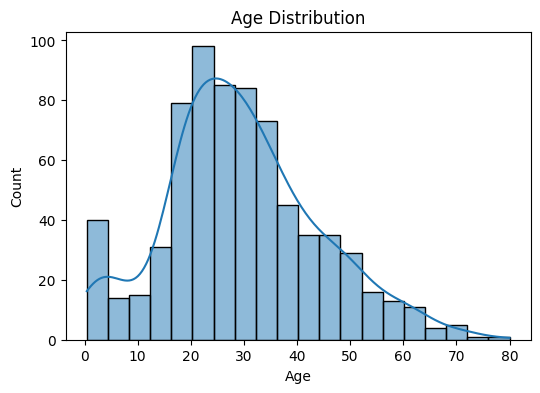

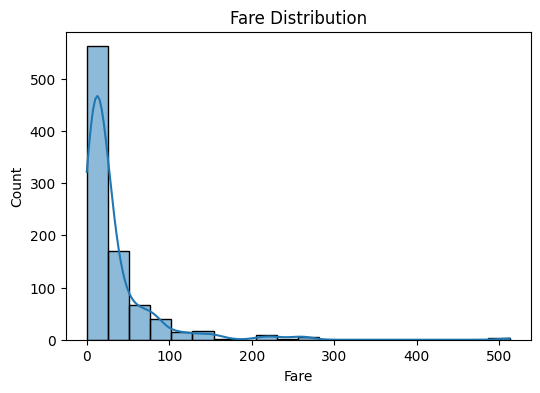

In [7]:
numeric_only = ['Age','Fare']
for col in numeric_only:
    plt.figure(figsize = (6,4))
    sns.histplot(df[col],kde = True, bins = 20)
    plt.title(col + " Distribution")
    plt.show()

In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [10]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


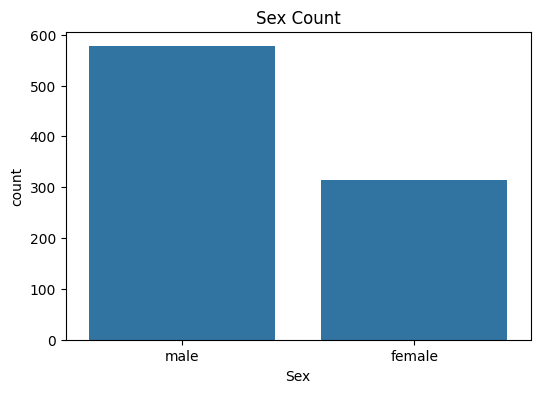

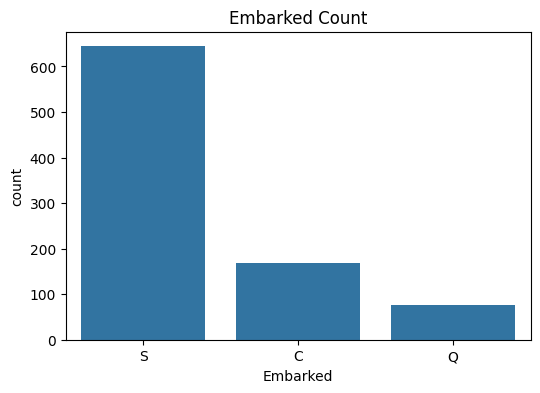

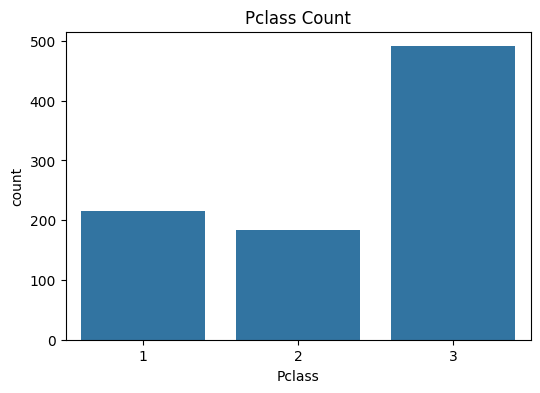

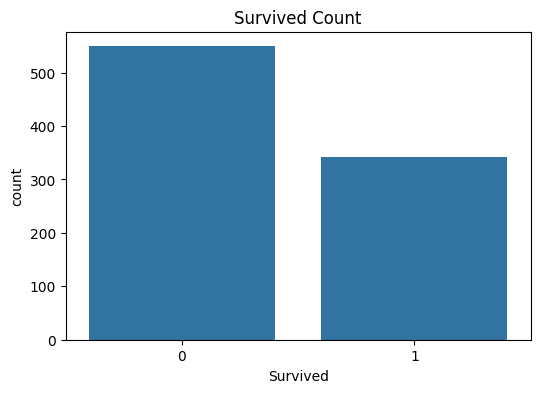

In [14]:
categorical_columns = ["Sex", "Embarked", "Pclass", "Survived"]

for col in categorical_columns:
    plt.figure(figsize=(6, 4))

    sns.countplot(x=df[col])

    plt.title(col + " Count")
    plt.show()

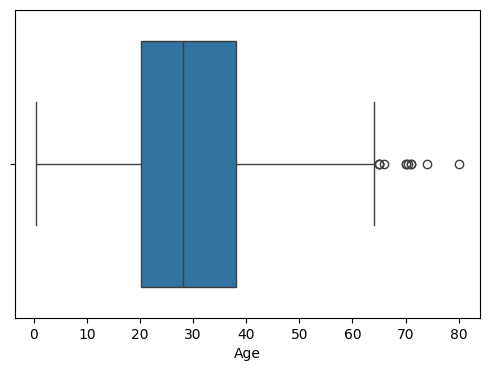

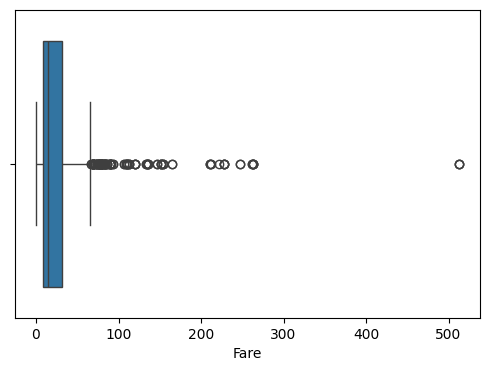

In [15]:
numeric_only = ['Age','Fare']
for col in numeric_only:
    plt.figure(figsize = (6,4))
    sns.boxplot(x = df[col])
    

In [16]:
df["Age"] = df["Age"].fillna(df["Age"].mean())

print(df["Age"])

0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    29.699118
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64


In [17]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print(df["Embarked"])

0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 891, dtype: object


# As there are more than half values that are still unknown so we can't just simply drop the column instaed we can make a new column which can show which passengers have there cabin number mentioned and which are not which can help the model predict if the passenger survived or not

In [18]:
df['Cabin_known'] = df['Cabin'].notnull().astype(int)

print(df['Cabin_known'])

0      0
1      1
2      0
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Cabin_known, Length: 891, dtype: int64


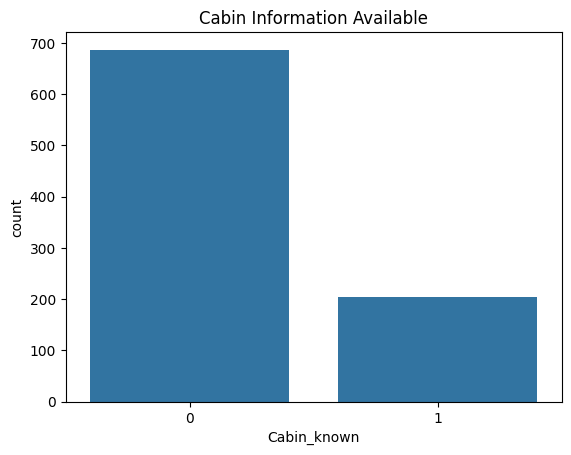

In [19]:
sns.countplot(x=df["Cabin_known"])

plt.title("Cabin Information Available")
plt.show()

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     891 non-null    object 
 12  Cabin_known  891 non-null    int64  
dtypes: float64(2), int64(6), object(5)
memory usage: 90.6+ KB


In [21]:
df.head


<bound method NDFrame.head of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex        Age  \
0                              Braund, Mr. Owen Harris    male  22.000000   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.000000   
2                               Heikkinen, Miss. Laina  female  26.000000   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.000000   
4                             Allen, Mr. William Henry    male  35.000000   
..                                                 

# * As we have performed the EDA now we are prepraing the data for machine 

In [22]:
# we are going to drop the passenger id column as it is just an identifier, there is no need of this for training the ML model.
df = df.drop(columns = "PassengerId")

# dropping the name column as it is irrelevant to model training
df = df.drop(columns = "Name")

# Performing Label Encoding to make it machine readable
df['Sex'] = df['Sex'].map({'male':0, 'female': 1})

# Applying One Hot Encoding to convert this categorical column 

In [23]:
# Embarked column has multiple values so we need to convert them into individual 

df = pd.get_dummies(df, columns = ['Embarked'], dtype = int)


In [24]:
df.head()


,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Cabin_known,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,A/5 21171,7.2500,NaN,0,0,0,1
1,1,1,1,38.0,1,0,PC 17599,71.2833,C85,1,1,0,0
2,1,3,1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,0,0,1
3,1,1,1,35.0,1,0,113803,53.1000,C123,1,0,0,1
4,0,3,0,35.0,0,0,373450,8.0500,NaN,0,0,0,1


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Survived     891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Sex          891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Cabin        204 non-null    object 
 9   Cabin_known  891 non-null    int64  
 10  Embarked_C   891 non-null    int64  
 11  Embarked_Q   891 non-null    int64  
 12  Embarked_S   891 non-null    int64  
dtypes: float64(2), int64(9), object(2)
memory usage: 90.6+ KB


In [26]:
df = df.drop(columns = "Cabin")

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Survived     891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Sex          891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Cabin_known  891 non-null    int64  
 9   Embarked_C   891 non-null    int64  
 10  Embarked_Q   891 non-null    int64  
 11  Embarked_S   891 non-null    int64  
dtypes: float64(2), int64(9), object(1)
memory usage: 83.7+ KB


In [28]:
df["Ticket"].head(10)

0           A/5 21171
1            PC 17599
2    STON/O2. 3101282
3              113803
4              373450
5              330877
6               17463
7              349909
8              347742
9              237736
Name: Ticket, dtype: object

In [29]:
df["Ticket"].nunique()

681

In [30]:
# Check the most common tickets
df["Ticket"].value_counts().head(10)

Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
113760          4
19950           4
Name: count, dtype: int64

In [31]:
df["TicketGroupSize"] = df.groupby("Ticket")["Ticket"].transform("count")

In [32]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [33]:
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

In [34]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin_known,Embarked_C,Embarked_Q,Embarked_S,TicketGroupSize,FamilySize,IsAlone
0,0,3,0,22.0,1,0,A/5 21171,7.2500,0,0,0,1,1,2,0
1,1,1,1,38.0,1,0,PC 17599,71.2833,1,1,0,0,1,2,0
2,1,3,1,26.0,0,0,STON/O2. 3101282,7.9250,0,0,0,1,1,1,1
3,1,1,1,35.0,1,0,113803,53.1000,1,0,0,1,2,2,0
4,0,3,0,35.0,0,0,373450,8.0500,0,0,0,1,1,1,1


In [35]:
df = df.drop(columns = "Ticket")

In [36]:
df = pd.get_dummies(df, columns = ["Pclass"], dtype = int)

In [37]:
df.head()

,Survived,Sex,Age,SibSp,Parch,Fare,Cabin_known,Embarked_C,Embarked_Q,Embarked_S,TicketGroupSize,FamilySize,IsAlone,Pclass_1,Pclass_2,Pclass_3
0,0,0,22.0,1,0,7.2500,0,0,0,1,1,2,0,0,0,1
1,1,1,38.0,1,0,71.2833,1,1,0,0,1,2,0,1,0,0
2,1,1,26.0,0,0,7.9250,0,0,0,1,1,1,1,0,0,1
3,1,1,35.0,1,0,53.1000,1,0,0,1,2,2,0,1,0,0
4,0,0,35.0,0,0,8.0500,0,0,0,1,1,1,1,0,0,1


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Survived         891 non-null    int64  
 1   Sex              891 non-null    int64  
 2   Age              891 non-null    float64
 3   SibSp            891 non-null    int64  
 4   Parch            891 non-null    int64  
 5   Fare             891 non-null    float64
 6   Cabin_known      891 non-null    int64  
 7   Embarked_C       891 non-null    int64  
 8   Embarked_Q       891 non-null    int64  
 9   Embarked_S       891 non-null    int64  
 10  TicketGroupSize  891 non-null    int64  
 11  FamilySize       891 non-null    int64  
 12  IsAlone          891 non-null    int64  
 13  Pclass_1         891 non-null    int64  
 14  Pclass_2         891 non-null    int64  
 15  Pclass_3         891 non-null    int64  
dtypes: float64(2), int64(14)
memory usage: 111.5 KB


In [39]:
from sklearn.model_selection import train_test_split

X = df.drop("Survived", axis=1)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [41]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [42]:
y_pred = model.predict(X_test_scaled)
print(y_pred)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(10))


[0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0
 0 0 1 0 1 0 1 1 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 1 0 0 1 1 1 0 0 0 1 0 1 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 1 0 0 0 1 0
 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0
 1 1 0 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 0 0 1 1 0 0 0 0 1 0 0 1 0]
   Actual  Predicted
0       0          0
1       0          0
2       1          0
3       0          0
4       1          1
5       1          0
6       1          1
7       0          0
8       0          0
9       0          0


In [43]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.8044692737430168


In [44]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[96 14]
 [21 48]]


In [45]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.87      0.85       110
           1       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [46]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [48]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [49]:
rf_pred = rf_model.predict(X_test)

In [50]:
print(rf_pred[:10])

[0 0 0 0 1 0 0 1 1 0]


In [51]:
rf_comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_pred
})

print(rf_comparison.head(10))

   Actual  Predicted
0       0          0
1       0          0
2       1          0
3       0          0
4       1          1
5       1          0
6       1          0
7       0          1
8       0          1
9       0          0


In [52]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7653631284916201


In [53]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, rf_pred)

print(rf_cm)

[[94 16]
 [26 43]]


In [54]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.78      0.85      0.82       110
           1       0.73      0.62      0.67        69

    accuracy                           0.77       179
   macro avg       0.76      0.74      0.74       179
weighted avg       0.76      0.77      0.76       179



In [55]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

            Feature  Importance
0               Sex    0.233746
1               Age    0.221490
4              Fare    0.213729
9   TicketGroupSize    0.061857
5       Cabin_known    0.045827
14         Pclass_3    0.041792
10       FamilySize    0.034404
12         Pclass_1    0.028480
2             SibSp    0.027175
3             Parch    0.026366
8        Embarked_S    0.020048
6        Embarked_C    0.013243
13         Pclass_2    0.012088
11          IsAlone    0.011901
7        Embarked_Q    0.007855


In [56]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "Survivor F1-Score": [0.73, 0.67]
})

print(model_comparison)

                 Model  Accuracy  Survivor F1-Score
0  Logistic Regression  0.804469               0.73
1        Random Forest  0.765363               0.67


## Model Comparison and Evaluation

I trained and evaluated two classification models on the Titanic dataset: Logistic Regression and Random Forest.

The results are:

| Model | Accuracy | Survivor F1-Score |
|---|---:|---:|
| Logistic Regression | 80.45% | 0.73 |
| Random Forest | 76.54% | 0.67 |

### Observations

- Logistic Regression achieved higher accuracy than Random Forest.
- Logistic Regression also achieved a higher F1-score for predicting survivors.
- Random Forest did not outperform Logistic Regression in this experiment.
- A more complex model does not necessarily produce better results.

### Conclusion

Based on this train-test split, Logistic Regression performed better than Random Forest on both evaluation metrics.

This suggests that Logistic Regression is a stronger model for this particular experiment. Further testing and model tuning could help determine whether performance can be improved.